# 02 · Model Comparison and Error Analysis

Both models are compared on the **same 1,000-example test set**:
1. **TF-IDF + Logistic Regression** (baseline)
2. **BERTurk** (`dbmdz/bert-base-turkish-cased`, fine-tuned)

Predictions are read from `reports/preds_*.csv`; the models are not re-run here. The label `Notr` is the dataset's spelling of **Neutral**.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import classification_report
from src.config import LABELS, REPORTS_DIR
from src.evaluate import load_preds, results_table
pd.set_option('display.max_colwidth', 200)
preds = load_preds()
results_table(preds).round(4)

,Model,Accuracy,Macro F1,F1 (Neg+Pos),Train time (s)
0,TF-IDF + LogReg,0.882,0.8249,0.7607,7.2
1,BERTurk,0.948,0.9103,0.8669,1777.6


**Metrics:**
- **Accuracy:** share of correct predictions. On imbalanced data it can be inflated by the majority class.
- **Macro F1:** unweighted mean of per-class F1 scores; the minority class (Negative) counts equally.
- **F1 (Neg+Pos):** only the real sentiment classes. As the EDA showed, the Neutral class consists solely of Wikipedia sentences and is therefore easy; this metric shows how well the model actually separates sentiment.

In [2]:
for name, df in preds.items():
    print(f'=== {name} ===')
    print(classification_report(df['label'], df['pred'], labels=LABELS, digits=3))

=== TF-IDF + LogReg ===
              precision    recall  f1-score   support

    Negative      0.586     0.678     0.629       115
        Notr      0.918     0.991     0.953       351
    Positive      0.934     0.854     0.892       534

    accuracy                          0.882      1000
   macro avg      0.813     0.841     0.825      1000
weighted avg      0.889     0.882     0.884      1000

=== BERTurk ===
              precision    recall  f1-score   support

    Negative      0.783     0.783     0.783       115
        Notr      0.994     1.000     0.997       351
    Positive      0.953     0.949     0.951       534

    accuracy                          0.948      1000
   macro avg      0.910     0.911     0.910      1000
weighted avg      0.948     0.948     0.948      1000



## Confusion matrices
Rows are the true class, columns the prediction. Off-diagonal cells are errors.

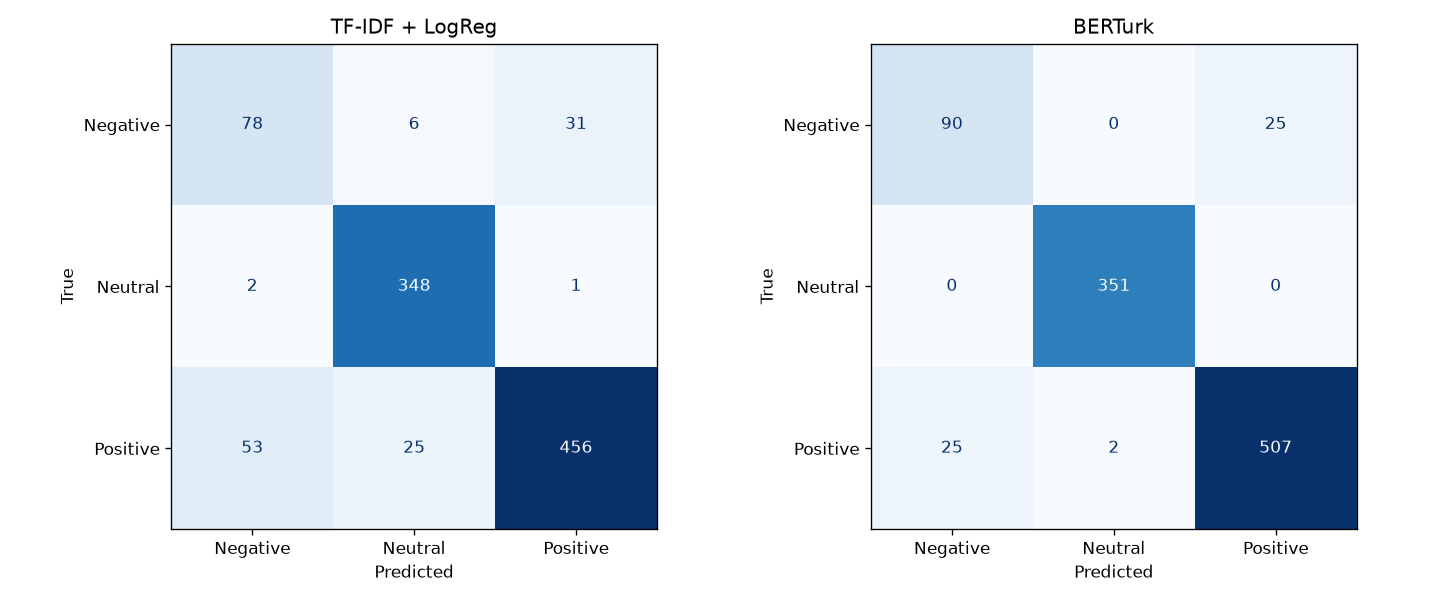

In [3]:
display(Image(filename=str(REPORTS_DIR / 'confusion_matrices.png')))

## Accuracy by source
Which kinds of text are hard for the models?

In [4]:
pd.DataFrame({name: df.assign(ok=df['label'] == df['pred']).groupby('dataset')['ok'].mean()
              for name, df in preds.items()}).assign(n=preds['BERTurk']['dataset'].value_counts()).round(3)

,TF-IDF + LogReg,BERTurk,n
dataset,,,
HUMIR,0.740,0.885,131
magaza_yorumlari,0.545,0.773,22
tweet-pn,0.292,0.667,24
urun_yorumlari,0.886,0.949,472
wiki,0.991,1.000,351


## Where do the two models disagree?

In [5]:
b, t = preds['TF-IDF + LogReg'], preds['BERTurk']
b_ok, t_ok = b['label'] == b['pred'], t['label'] == t['pred']
print('Both correct         :', (b_ok & t_ok).sum())
print('Only BERTurk correct :', (~b_ok & t_ok).sum())
print('Only baseline correct:', (b_ok & ~t_ok).sum())
print('Both wrong           :', (~b_ok & ~t_ok).sum())
t.assign(baseline_pred=b['pred'])[~b_ok & t_ok][['text', 'label', 'baseline_pred', 'pred']].head(8)

Both correct         : 871
Only BERTurk correct : 77
Only baseline correct: 11
Both wrong           : 41


,text,label,baseline_pred,pred
11,"bir yönetmene neden usta denilebileceğinin apaçık örneği...geçenlerde arkadaşımla sinemada yönetmenlik konusunda sohbet ediyorduk,'eskiden yönetmenler sinema sanatına yakışır eserler üretiyorlardı...",Positive,Negative,Positive
15,bence film başarılı fakat öyle çok ta farklı bir film değil bence. yaratıcılık göremedim sıradan sayılabilecek bir film ama yinede başarılı,Positive,Negative,Positive
30,"bu film denzicilerin ağıtıdır.yalnızlığıdır.görsel efektler,müzik ve oyunculuklar son derece güzel.",Positive,Negative,Positive
53,-ekranın kenarları kavisli olduğu için piyasadaki ekran filmleri ve camlarının %90ı ekranı tam olarak kaplamıyor.,Positive,Negative,Positive
79,harikabaşta yemekler sonra havuzlar sonra animasyon çok iyi ayrıca odamızı temizleyenlere ve servis elemanlarına çok teşekkür ederiz otel denize yakın değil ama servisleri var dk denizdesiniz bar...,Positive,Negative,Positive
84,"4- sacı sağlam, takıldıktan sonra esneme veya sallanma yok.",Positive,Notr,Positive
92,Kapak tırnağı kırık olmasa ürünün kalitesine gölge düşmemiş olurdu,Positive,Notr,Positive
93,film yüzüklerin efendisine yakışıcak bir son filmiydi.on üzerinden onlukdu.filmi izlerken çok keyif almıştım.bu yorumumda geç geldi ama yazamadan duramadım.herşeyi ile güzel bir film.,Positive,Negative,Positive


## Error analysis: 20 BERTurk mistakes
We take the misclassified examples sorted by the model's **confidence, highest first**. Confident mistakes are usually the most informative: either the label is wrong, or the model is missing something systematic. The `note` column explains the likely cause for each example (the texts themselves are in Turkish).

In [6]:
err = pd.read_csv(REPORTS_DIR / 'error_analysis.csv')
err[['text', 'label', 'pred', 'confidence', 'dataset', 'category', 'note']]

,text,label,pred,confidence,dataset,category,note
0,sünger kalitesi olarak çok üst düzey olduğunu söyleyemem ama fiyat fayda ilişkisi gözetildiğinde tercih edilebilir. büyüklük yeterli. gönderim konusunda bir sorun yaşamadım. hb tşk.,Negative,Positive,0.997040,urun_yorumlari,Mixed sentiment,"Criticizes quality but praises price and shipping. The label probably comes from the star rating; the positive words in the text ('worth choosing', 'no problems', 'thanks') dominate."
1,Açık görüş yasağı işkenceye dönüştü!,Positive,Notr,0.996892,tweet-pn,Questionable label,"'Turned into torture' is clearly negative, yet the label is Positive -> label error. The model said Neutral: a short headline-like sentence resembles the Wikipedia style."
2,akıllı tahta da kullanıyorum ara sıra küçük donmalar yasıyorum ama bilgisayarın cok yakınında olanlar icin iyi bir urun birde capslook isigi diye birşey yok deneme yanılma ile anlıyorsun bir müdde...,Negative,Positive,0.995782,urun_yorumlari,Mixed sentiment,'small freezes ... but a good product': complaint and praise together; the model weighted the 'good product' part.
3,ürünü denedim en yüksek şiddette fena değil ama direk mekik türlerini yapmak bence daha faydalı.en güzeli doğal şekilde spor yapmak.,Negative,Positive,0.995428,urun_yorumlari,Mixed sentiment,'Not bad' (mildly positive) plus a suggestion to use an alternative. The negativity is indirect; the label is debatable.
4,Bu ürünle birlikte JBL kablosuz kulaklık aldım. Onun ses kalitesi daha\niyi. Aldanmayın,Negative,Positive,0.994879,magaza_yorumlari,Indirect statement / comparison,"The negativity comes through a comparison with another product ('its sound quality is better', 'don't be fooled'). The positive words describe a different product; the model could not resolve that..."
5,"yani sonuçta uygun bir havlu, eli kuruluyor :) ancak çok ciddi bir tüketim yok ise ben bir iki basamak daha kaliteli havlu tavsiye ederim. tabi bir parça yetmiyor ikincisini alıyorsunuz, belki dah...",Negative,Positive,0.994437,urun_yorumlari,Mixed sentiment,"Starts positive ('a decent towel, it dries your hands :)'); the criticism is phrased as a recommendation ('I'd recommend a better towel'). 'I recommend' is also one of the baseline's strongest Pos..."
6,1. düğmeden ayarlı hız kademesi.,Positive,Notr,0.993796,urun_yorumlari,Source shortcut (Neutral = encyclopedic style),"A short, emotion-free factual sentence ending with a period; in the training data this style only appears in the Neutral (Wikipedia) class. The label is also debatable (Positive, but the sentence ..."
7,düşük kaliteli,Negative,Positive,0.993065,urun_yorumlari,Negation / very short text,Only two words: 'low quality'. 'Quality' appears very often in positive product reviews; the modifier 'low' was not learned from so little data. A short text gives no context.
8,urun 8 gunde elime ulasti. kargolamayi super yapmislar. zarar girmemis. ama avizenin alt kisminda desenlerinde silik ve kaymalar mevcut. kutusunun icinden kurulumla alakali bir tek satir yazi bil...,Negative,Positive,0.992925,urun_yorumlari,Mixed sentiment,"Praises the shipping first ('they packed it great'), then describes a product defect. The model was swayed by the positive opening."
9,"3-ekran koruyucu olarak kesinlikle algılanması darbelerden değil cep,çantada vb,, içindeki çizikleren koruyor afif şiddetleri emiyor.",Negative,Positive,0.992524,urun_yorumlari,Questionable label,"The text explains what the screen protector protects against, with no clear negativity -> the label probably comes from a low rating; the text alone does not support Negative."


In [7]:
err['category'].value_counts()

category
Mixed sentiment                                   9
Questionable label                                6
Indirect statement / comparison                   3
Source shortcut (Neutral = encyclopedic style)    1
Negation / very short text                        1
Name: count, dtype: int64

## Conclusions
- **Almost half of the confident errors are mixed-sentiment reviews** (e.g. "shipping was great but the product is bad"). The labels likely come from star ratings, so the correct answer is debatable; aspect-based sentiment would fit better.
- **About a third have questionable labels**, so the model's true error rate is somewhat lower than reported.
- The model **over-weights positive phrases at the start** of a review and **cannot handle irony**.
- The Neutral class is solved almost perfectly only because of the **Wikipedia shortcut** described in the EDA.